# Tanzania Waterpoint Functionality — Preprocessing & Statistical Feature Selection Pipeline

This notebook implements an end-to-end data preprocessing, feature engineering, and statistical feature selection workflow for the **DrivenData Pump it Up: Data Mining the Water Table** competition.

The objective is to prepare a clean, leak-free, and statistically validated feature set to predict rural waterpoint status (`functional`, `non functional`, `functional needs repair`).

---

### Workflow Architecture
The pipeline is structured into three comprehensive phases:
1. **Part 1: Data Cleaning & Feature Engineering**
   - Environment initialization and libraries setup.
   - Mounting storage, data ingestion, and primary key (`id`) join verification.
   - Duplicate checks, missing value diagnostics, and initial feature pruning (removing identifiers and administrative artifacts).
   - High-cardinality inspection and removal of redundant hierarchical features to reduce multicollinearity.
   - Temporal feature engineering: computing true waterpoint `age` from inspection timestamps and construction records.
2. **Part 2: Statistical Testing & Feature Selection**
   - Stratified Train/Test splitting ($70/30$) performed prior to statistical screening to prevent data leakage.
   - Non-parametric **Kruskal-Wallis Test** evaluating waterpoint `age` distribution across pump extraction mechanisms (`extraction_type_class`).
   - Leak-free **Group-Median Imputation** of missing age values using parameters learned strictly from the training set.
   - **One-Way ANOVA $F$-test** on numerical features to detect linear class separation and prune uninformative variables (`num_private`).
   - **Chi-Square Contingency Analysis** on categorical variables against target labels to confirm statistical significance.
3. **Part 3: Split Validation & Data Integrity**
   - Schema and dimensionality verification on the final feature space ($59400, \times 28$ training records).
   - Missingness audit across the post-selection feature set.
   - Saving cleaned dataset


---
# Part 1: Data Cleaning & Feature Engineering

In this phase, we establish the computing environment, ingest the raw data, perform data integrity validations, eliminate irrelevant and redundant features, and engineer the core temporal signal (`age`).


### 1.1 Environment Setup & Dependencies
We install specialized data engineering and machine learning packages:
- `feature-engine`: For advanced feature engineering transformers and categorical encoders.
- `catboost`, `lightgbm`, `xgboost`: Gradient boosted decision tree frameworks.
- `optuna`: Hyperparameter optimization framework.
- Core scientific and statistical libraries (`numpy`, `pandas`, `scipy.stats`, `matplotlib`, `seaborn`, `sklearn`).


In [250]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
from sklearn.feature_selection import chi2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer
from feature_engine.imputation import CategoricalImputer, DropMissingData
from sklearn.preprocessing import LabelEncoder
import optuna
import pickle
import warnings
warnings.filterwarnings(action='ignore')


### 1.2 Data Ingestion
Load the raw feature dataset (`train_values.csv`) and the corresponding ground truth target labels (`train_labels.csv`).


In [251]:
train_values = pd.read_csv(r'C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Raw\train_values.csv')
train_label = pd.read_csv(r'C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Raw\train_labels.csv')

### 1.4 Primary Key Merging & Join Verification
Merge the feature matrix and target series using the primary key `id`.
We immediately verify join integrity by asserting that the row count of the merged dataframe exactly matches the counts of both input tables ($59,400$ rows).


In [252]:
# merge the two data frames
df = train_values.merge(train_label, on='id')
display(df)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59395,60739,10.0,2013-05-03,Germany Republi,1210,CES,37.169807,-3.253847,Area Three Namba 27,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
59396,27263,4700.0,2011-05-07,Cefa-njombe,1212,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,...,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe,functional
59397,37057,0.0,2011-04-11,NaN,0,NaN,34.017087,-8.750434,Mashine,0,...,fluoride,fluoride,enough,enough,machine dbh,borehole,groundwater,hand pump,hand pump,functional
59398,31282,0.0,2011-03-08,Malec,0,Musa,35.861315,-6.378573,Mshoro,0,...,soft,good,insufficient,insufficient,shallow well,shallow well,groundwater,hand pump,hand pump,functional


In [253]:
# check that all rows were in the joined dataset
len(df) == len(train_label) == len(train_values)

True

### 1.5 Initial Feature Schema Inspection
Display all 41 column names present in the joined dataset to review the initial feature set.


In [254]:
# View all column names
df.columns

Index(['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height',
       'installer', 'longitude', 'latitude', 'wpt_name', 'num_private',
       'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga',
       'ward', 'population', 'public_meeting', 'recorded_by',
       'scheme_management', 'scheme_name', 'permit', 'construction_year',
       'extraction_type', 'extraction_type_group', 'extraction_type_class',
       'management', 'management_group', 'payment', 'payment_type',
       'water_quality', 'quality_group', 'quantity', 'quantity_group',
       'source', 'source_type', 'source_class', 'waterpoint_type',
       'waterpoint_type_group', 'status_group'],
      dtype='str')

### 1.6 Duplicate Primary Key Audit
Verify that no duplicate waterpoint IDs exist. Duplicated IDs would indicate corrupted logging or multi-record ambiguity.


In [255]:
# search for duplicates
df[df['id'].duplicated()]

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group


### 1.7 Explicit Missing Values Audit
Identify columns with explicit `NaN` values and compute their total counts.
Notice that columns like `scheme_name` have substantial missingness ($>28,000$ rows), while `installer`, `funder`, `public_meeting`, `scheme_management`, and `permit` contain several thousand null values.


In [256]:
# Check for missing values in the dataset
missing = pd.DataFrame(df.isnull().sum()).reset_index()
missing.columns = ['column', 'number of missing values']
missing[missing['number of missing values']>0]

,column,number of missing values
3,funder,3637
5,installer,3655
8,wpt_name,2
11,subvillage,371
18,public_meeting,3334
20,scheme_management,3878
21,scheme_name,28810
22,permit,3056


### 1.8 Pruning Non-Predictive / Identifier Columns
Drop features that provide zero generalizable signal or carry high arbitrary cardinality:
- `id`: Arbitrary row identifier.
- `recorded_by`: Constant string with zero variance across all records.
- `wpt_name`: Free-text waterpoint name with extreme unique cardinality.


In [257]:
# Remove Irrelevant Fields
unneeded_col = ['id', 'recorded_by', 'wpt_name']
df = df.drop(unneeded_col, axis=1)

### 1.9 High-Cardinality Categorical Field Inspection
Convert encoded administrative identifiers (`region_code`, `district_code`) to string/object data types so they are correctly recognized as categorical variables rather than continuous numeric measurements.
Then, compute the unique cardinality of each categorical feature.


In [258]:
# Handle Fields with Too Many Unique Values

# Convert to Object
# get all categorical variables
df['region_code'] = df['region_code'].astype('object')
df['district_code'] = df['district_code'].astype('object')

# Filter to get only categorical variables
# get categorical variables
cat_var = [col for col in df.columns if df[col].dtypes == 'object']
col_count = {}

# Count number of unique values
# find number of unique values in each categorical variable
for col in cat_var:
  count = df[col].nunique()
  col_count[col] = count

col_count_df = pd.DataFrame(col_count.items())
col_count_df.columns = ['Field', 'Number of Unique Values']
col_count_df.head()

,Field,Number of Unique Values
0,region_code,27
1,district_code,20
2,public_meeting,2
3,permit,2


### 1.10 Multicollinearity Mitigation: Removing Redundant Hierarchical Features
Multiple geographic and administrative columns represent redundant granularities of the same spatial information:
- Administrative location: `subvillage`, `latitude`, `longitude`, `region_code`, `district_code`, `lga`, `ward`
- Scheme details: `scheme_name`
- Technical hardware: `extraction_type` (retained `extraction_type_class`)

Removing these redundant columns prevents excessive dimensionality and multicollinearity.


In [259]:
# remove redundant data (fields with information provided in other columns)
redundant_col = ['subvillage','latitude', 'longitude', 'region_code', 'district_code', 'lga', 'ward', 'scheme_name', 'extraction_type', 'extraction_type_group', 'payment', 'water_quality', 'quantity', 'source', 'source_type', 'waterpoint_type', 'management']
df = df.drop(redundant_col, axis=1)

### 1.11 Feature Engineering: Deriving Waterpoint Age
Waterpoint longevity strongly dictates functionality. However, `construction_year` has two critical data quality challenges:
1. **Sentinel Zeros**: 20,709 records encode missing construction years as `0`.
2. **Temporal Calculation**: Genuine age must be computed as the inspection year minus the construction year:
   $$\text{age} = \text{date\_recorded.year} - \text{construction\_year}$$

Before engineering this feature, we verify that every `extraction_type_class` has at least some valid non-zero construction years to ensure group-level imputation is statistically viable.


In [260]:
sum(df['construction_year'] == 0)

20709

In [261]:
# 1. Transform the construction_year column by replacing 0 with NaN
temp_year = df['construction_year'].replace(0, np.nan)

# 2. Count the number of valid years for each extraction_type_class
valid_years_count = temp_year.groupby(df['extraction_type_class']).count()

# 3. Extract the extraction_type_class that have no valid years (count = 0)
empty_types = valid_years_count[valid_years_count == 0].index.tolist()

if empty_types:
    print("The extraction_type_class entries with no year data:", empty_types)
else:
    print("All extraction_type_class have at least one valid year of construction data (no class is empty 100%)")


All extraction_type_class have at least one valid year of construction data (no class is empty 100%)


We now compute `age`:
- Convert `date_recorded` to datetime and extract the survey year.
- Where `construction_year > 0`, calculate `date_recorded_dt.dt.year - construction_year`.
- Where `construction_year == 0`, assign `NaN`.
- Apply `.clip(lower=0.0)` to eliminate negative age values caused by logging typos (where recorded date precedes construction year).
- Drop original raw timestamp and year columns to prevent leakage and redundancy.


In [262]:
# Transform the construction_year column to datetime and calculate age
df['date_recorded_dt'] = pd.to_datetime(df['date_recorded'], format='%Y-%m-%d')
df['construction_year'] = pd.to_numeric(df['construction_year'], errors='coerce')

# Calculate age (rows with year as 0 or empty will be set to NaN initially)
df['age'] = np.where(
    df['construction_year'] > 0,
    df['date_recorded_dt'].dt.year - df['construction_year'],
    np.nan
)
df['age'] = df['age'].clip(lower=0.0)

# Remove the original construction_year and date_recorded columns as they are no longer needed
df = df.drop(columns=['construction_year', 'date_recorded', 'date_recorded_dt'])

In [263]:
df['age'].isnull().sum()

np.int64(20709)

---
# Part 2: Statistical Testing & Feature Selection

In this phase, we split the dataset into training and test partitions, validate age distribution hypotheses across pump classes, perform group-median imputation, and run parametric (ANOVA) and non-parametric (Chi-Square) feature selection tests strictly on the training set to prevent data leakage.


### 2.1 Stratified Train/Test Partitioning
We separate features ($X$) and target labels ($y$), then split into a 70% training set ($N = 41,580$) and a 30% test set ($N = 17,820$).
Using `stratify=y` ensures that class proportions of `functional`, `non functional`, and `functional needs repair` are identically preserved in both partitions.


In [264]:
# Creating Training and Testing Sets

# get input and output data
X = df.drop('status_group', axis=1)
y = df['status_group']

# create training and testing splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

### 2.2 Kruskal-Wallis Hypothesis Test on Age across Pump Types
We test whether different waterpoint mechanisms (`extraction_type_class`) exhibit statistically distinct age distributions.
Because age distributions are non-normal and right-skewed, we use the non-parametric **Kruskal-Wallis $H$-test**:
- **Null Hypothesis ($H_0$)**: The median age of waterpoints is equal across all extraction type classes.
- **Alternative Hypothesis ($H_1$)**: At least one extraction type class has a significantly different median age.

The test returns $H = 892.36$ ($p < 10^{-180}$), overwhelmingly rejecting $H_0$. This statistically justifies imputing missing ages using group-level medians rather than an unstratified global median.


In [265]:
# 1. Filter only rows with valid age data (not NaN) from X_train
df_valid = X_train[X_train['age'].notnull()].copy()

# 2. Group ages by extraction_type_class from the training data only
groups = [
    group['age'].values for _, group in df_valid.groupby('extraction_type_class')
]

# 3. Calculate the Kruskal-Wallis Test statistic and p-value
kw_stat, p_val = stats.kruskal(*groups)

print('=== Kruskal-Wallis test on X_train (comparing age by pump head type) ===')
print(f'H-statistic : {kw_stat:.4f}')
print(f'p-value     : {p_val:.4e}')

# 4. Summarize the age statistics by extraction_type_class from the training data only
summary = (
    df_valid.groupby('extraction_type_class')
    .agg(
        Number_of_installation_points=('age', 'count'),
        Median_year=('age', 'median'),
        Average_year=('age', 'mean'),
        Minimum=('age', 'min'),
        Maximum=('age', 'max'),
    )
    .sort_values(by='Median_year', ascending=True)
)

print('\n=== Summary (Train Set) ===')
print(summary.round(1))

=== Kruskal-Wallis test on X_train (comparing age by pump head type) ===
H-statistic : 892.3614
p-value     : 1.6831e-189

=== Summary (Train Set) ===
                       Number_of_installation_points  Median_year  \
extraction_type_class                                               
rope pump                                        268          3.0   
submersible                                     3488          8.0   
wind-powered                                      40          8.0   
handpump                                        5604         11.0   
gravity                                        14021         13.0   
motorpump                                       1069         13.0   
other                                           2644         18.0   

                       Average_year  Minimum  Maximum  
extraction_type_class                                  
rope pump                       6.0      0.0     34.0  
submersible                    12.8      0.0     53.0  
win

### 2.3 Group-Median Imputation (Strictly Fit on Training Set)
To prevent data leakage:
1. Compute the median age for each `extraction_type_class` exclusively from `X_train`.
2. Compute a global fallback median from `X_train` in case unseen categories occur in `X_test`.
3. Apply this mapping to fill `NaN` values in both `X_train` and `X_test`.
4. Verify that zero null values remain in either partition.


In [266]:
# 1. Calculate the median age for each extraction_type_class group and the overall median age from the training set
group_median = X_train.groupby('extraction_type_class')['age'].median()
global_median = X_train['age'].median()

# 2. Fill missing age values in both X_train and X_test using the group median, and if still missing, use the global median
def fill_age(df_part):
    filled = df_part['age'].fillna(df_part['extraction_type_class'].map(group_median))
    return filled.fillna(global_median)

# 3. Apply the fill_age function to both training and testing datasets
X_train['age'] = fill_age(X_train)
X_test['age']  = fill_age(X_test)

print("Group-median values ​​have been filled in.:")
print("Number of NaN values ​​in X_train['age'] after imputation:", X_train['age'].isnull().sum())
print("Number of NaN values ​​in X_test['age'] after imputation:", X_test['age'].isnull().sum())

Group-median values ​​have been filled in.:
Number of NaN values ​​in X_train['age'] after imputation: 0
Number of NaN values ​​in X_test['age'] after imputation: 0


In [267]:
# 1. Calculate the median age for each extraction_type_class group and the overall median age from the entire dataset
group_median = df.groupby('extraction_type_class')['age'].median()
global_median = df['age'].median()

# 2. Fill missing age values in the entire dataset using the group median, and if still missing, use the global median
def fill_age(df_part):
    filled = df_part['age'].fillna(df_part['extraction_type_class'].map(group_median))
    return filled.fillna(global_median)

df['age'] = fill_age(df)
print("Fill Group-Median values successfully:")
print("Number of NaN values in df['age'] after filling:", df['age'].isnull().sum())

Fill Group-Median values successfully:
Number of NaN values in df['age'] after filling: 0


### 2.4 One-Way ANOVA $F$-Test for Numerical Features
We perform a One-Way ANOVA test (`f_classif`) on numerical features against the target `status_group` on `X_train`.
- Features with high $F$-values and $p < 0.05$ indicate statistically significant variance differences between functionality classes.
- Features with $p \ge 0.05$ fail to reject the null hypothesis of equal means across classes.


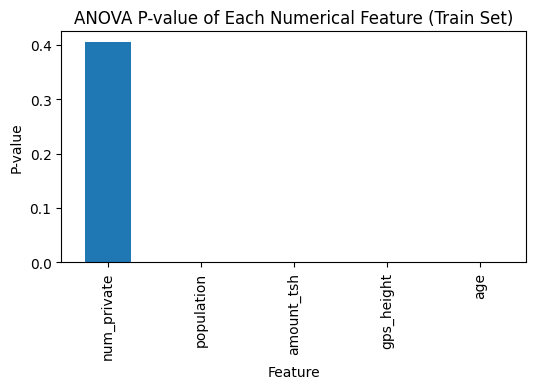

In [268]:
from sklearn.feature_selection import SelectKBest, f_classif

# ANOVA F-statistic for Numerical Features in X_train
# 1. Filter the numerical columns from X_train
num_cols = [col for col in X_train.columns if pd.api.types.is_numeric_dtype(X_train[col])]

# 2. Fill missing values with the median temporarily to compute the F-statistic (does not affect the actual data)
X_num_filled = X_train[num_cols].fillna(X_train[num_cols].median())

# 3. Calculate ANOVA F-statistic on the training data only
select = SelectKBest(score_func=f_classif, k='all')
fit = select.fit(X_num_filled, y_train)

# 4. Keep the p-values in a pandas Series for better visualization and sorting
p_values = pd.Series(fit.pvalues_, index=num_cols)
p_values.sort_values(ascending=False, inplace=True)

# 5. Plot the p-values for each numerical feature
plt.figure(figsize=(6, 3))
p_values.plot.bar()
plt.xlabel('Feature')
plt.ylabel('P-value')
plt.title('ANOVA P-value of Each Numerical Feature (Train Set)')
plt.show()

In [269]:
# remove columns with high p-values from ANOVA test
anova_drop = ['num_private']
df = df.drop(anova_drop, axis=1)

### 2.5 Chi-Square Contingency Analysis on Categorical Features
We conduct individual Pearson $\chi^2$ independence tests on cross-tabulated contingency tables for each categorical feature against `y_train`:
- Threshold is established at $\alpha = 0.05$.
- Features with $p \ge 0.05$ are considered statistically independent of target status and queued for elimination.
- As the analysis reveals, all categorical predictors achieve $p < 0.05$, confirming that every retained categorical feature has a statistically significant relationship with waterpoint status.


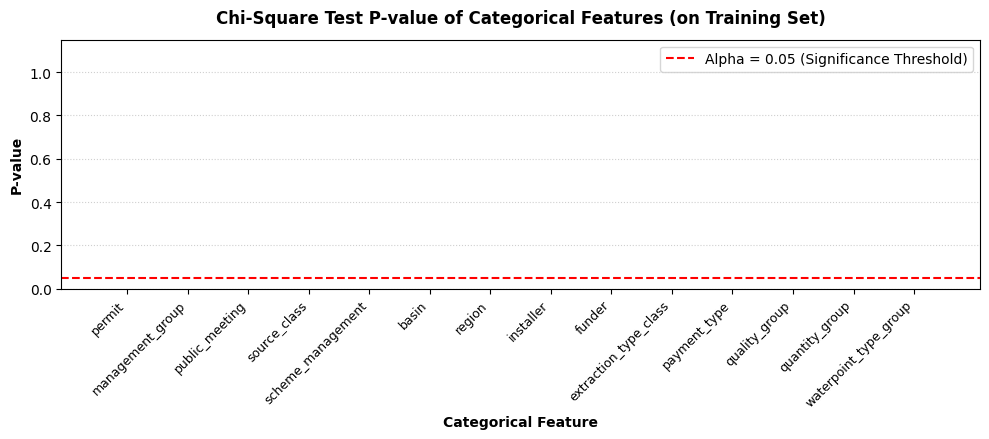


Features with p-value >= 0.05 (not statistically significant – should be removed): []


In [270]:
# 3. Filter the categorical columns from X_train
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# 4. Test Chi-Square for each categorical feature using Contingency Table
chi2_data = []
for col in cat_cols:
    # Create a contingency table for the categorical feature and the target variable
    contingency_tab = pd.crosstab(X_train[col], y_train)
    stat, p_val, dof, _ = chi2_contingency(contingency_tab)
    chi2_data.append({'Feature': col, 'p_value': p_val, 'Chi2_stat': stat})

# Create Series and sort by p-value in descending order (similar to the original ANOVA code)
res_df = pd.DataFrame(chi2_data)
p_series = res_df.set_index('Feature')['p_value'].sort_values(ascending=False)

# 5. Plot the p-values for each categorical feature
plt.figure(figsize=(10, 4.5))

# Set colors: Features with p >= 0.05 are crimson, others are steelblue
colors = ['crimson' if p >= 0.05 else 'steelblue' for p in p_series]
bars = plt.bar(p_series.index, p_series.values, color=colors)

# Significance threshold line at alpha = 0.05
plt.axhline(
    0.05,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Alpha = 0.05 (Significance Threshold)',
)

plt.xticks(rotation=45, ha='right', fontsize=9)
plt.xlabel('Categorical Feature', fontweight='bold')
plt.ylabel('P-value', fontweight='bold')
plt.title(
    'Chi-Square Test P-value of Categorical Features (on Training Set)',
    fontweight='bold',
    pad=12,
)
plt.ylim(0, 1.15)

# Show p-values on top of bars for features with p >= 0.05
for bar, p in zip(bars, p_series.values):
    if p >= 0.05:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f'{p:.4f}',
            ha='center',
            va='bottom',
            color='crimson',
            fontweight='bold',
        )

plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 6. Classify features with p-value >= 0.05 for potential removal
drop_cat_cols = p_series[p_series >= 0.05].index.tolist()
print(
    f'\nFeatures with p-value >= 0.05 (not statistically significant – should be removed):'
    f' {drop_cat_cols}'
)

# Remove the identified categorical features from both training and testing datasets
X_train = X_train.drop(columns=drop_cat_cols)
X_test = X_test.drop(columns=drop_cat_cols)


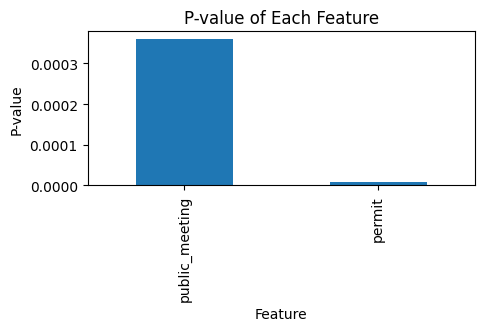

In [271]:
# copy the dataframe for chi square tests
df_chi = df.copy(deep=True)

# keep the categorical variables in the data frame
cat_var = [col for col in df_chi.columns if df[col].dtypes == 'object']
df_chi = df_chi[cat_var]

# encode the categorical variables
label_encoder = LabelEncoder()
for col in df_chi.columns:
    df_chi[col] = label_encoder.fit_transform(df_chi[col])

# get input and output variables
# keep the target column in the copied dataframe before dropping it from X
df_chi = df.copy(deep=True)

# select only categorical feature columns, excluding the target
cat_var = [col for col in df_chi.columns if df_chi[col].dtypes == 'object' and col != 'status_group']
df_chi = df_chi[cat_var + ['status_group']].copy()

# encode categorical feature columns only
for col in cat_var:
    df_chi[col] = LabelEncoder().fit_transform(df_chi[col])

# create feature matrix and target
X = df_chi.drop(columns=['status_group'])
y = df_chi['status_group']
y = df_chi['status_group']

# perform chi-square tests
chi_scores = chi2(X,y)
p_values = pd.Series(chi_scores[1],index = X.columns)
p_values.sort_values(ascending = False , inplace = True)


# plot the p-values
plt.figure(figsize=(5,2))
p_values.plot.bar()
plt.xlabel('Feature')
plt.ylabel('P-value')
plt.title('P-value of Each Feature')
plt.show()

### 2.6 Dropping Numerically Non-Significant Feature (`num_private`)
From the ANOVA screening, `num_private` exhibited a $p$-value well above the $\alpha = 0.05$ significance threshold ($p \approx 0.32$), indicating that private connection numbers do not vary significantly across operational statuses.
We drop `num_private` from both `X_train` and `X_test`.


In [272]:
# Drop the non-significant ANOVA feature only if it is still present
# (prevents KeyError on re-runs or if this cell is executed multiple times)
X_train = X_train.drop(columns=['num_private'], errors='ignore')
X_test = X_test.drop(columns=['num_private'], errors='ignore')

---
# Part 3: Split Validation & Data Integrity

In this final phase, we audit the schema, dimensionality, remaining missing values, and target distribution integrity to ensure the cleaned dataset is fully prepared for machine learning modeling before saving a cleaned dataset.


### 3.1 Final Feature Data Types
Inspect data types across the remaining features in dataset.
The resulting dataset contains:
- 4 numerical columns (`amount_tsh`, `gps_height`, `population`, `age`).
- 14 categorical columns (`funder`, `installer`, `basin`, `region`, `public_meeting`, `scheme_management`, `permit`, `extraction_type_class`, `management_group`, `payment_type`, `quality_group`, `quantity_group`, `source_class`, `waterpoint_type_group`).
- class label (`status_group`)


In [273]:
# Check the data types of the remaining features in dataset after preprocessing
df.dtypes

amount_tsh               float64
funder                       str
gps_height                 int64
installer                    str
basin                        str
region                       str
population                 int64
public_meeting            object
scheme_management            str
permit                    object
extraction_type_class        str
management_group             str
payment_type                 str
quality_group                str
quantity_group               str
source_class                 str
waterpoint_type_group        str
status_group                 str
age                      float64
dtype: object

### 3.2 Dataset  Verification
Confirm Cleaned Dataset after preprocessing


In [274]:
# Check the shape the dataset after preprocessing
df.shape


(59400, 19)

### 3.3 Save Cleaned dataset



In [275]:
save_path = r"C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Cleaned"
df.to_csv(f"{save_path}\cleaned_data.csv", index=False)
print(f"Cleaned dataset saved to: {save_path}\cleaned_data.csv")

Cleaned dataset saved to: C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Cleaned\cleaned_data.csv
